# Official fast.ai course22 original 05 — Colab adaptation

Original: [05-linear-model-and-neural-net-from-scratch.ipynb](https://github.com/fastai/course22/blob/230390584ba5b990e20487d68681a9ec5b258eff/clean/05-linear-model-and-neural-net-from-scratch.ipynb)

Pinned source commit: `230390584ba5b990e20487d68681a9ec5b258eff`. Source SHA256: `40f30499aa4c3a0cb73f621c0f2a810b375d8cf70e510de5b28030d9fdde1092`.

This additional notebook preserves the full original computational experiments. Existing independently written companions 00–07 remain separate. Set QUICK_RUN=False; run every code cell. Source notebooks and authorship belong to Jeremy Howard and fast.ai. No separate course22 repository license was found at the pinned commit; no fastbook license is applied to these files.

- Original Kaggle train/test data sourced from pinned public teaching copies. All891/418 passengers, column names, values and Name/Ticket/Cabin features verified against a second independent competition mirror; training values also equal the DataScienceDojo copy. No Kaggle provider checksum/terms acceptance/account score is claimed. Test labels remain unavailable.
- Pandas2 bool dummy columns converted explicitly to float32 before constructing tensors. Corrected argument order in sigmoid test prediction. Original full feature normalization before the split is retained as an identified teaching limitation. All six training experiments preserve epochs, learning rates, MAE objective and seed442; checkpoints/validation evidence added for every epoch/experiment.

Public publication and competition submission have not been performed. Saved predictions are learning artifacts; the 418 Titanic test targets are unavailable. Original conceptual prompts/headings are retained below.


In [1]:
# Colab setup. Run this cell before the exercise cells.
from pathlib import Path
import os, sys, zipfile

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
QUICK_RUN = False  #@param {type:"boolean"}
ARCHIVE_PATH = "/content/drive/MyDrive/HaiLong_Colab_Exercises_2026-10-03.zip"  #@param {type:"string"}

try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        if not Path('/content/drive/MyDrive').is_dir():
            drive.mount('/content/drive', timeout_ms=300000)
    COURSE_ROOT = Path('/content/HaiLong_Colab_Exercises')
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        archive = Path(ARCHIVE_PATH)
        if not archive.is_file():
            print('Select HaiLong_Colab_Exercises_2026-10-03.zip from your computer.')
            uploaded = files.upload()
            choices = [Path(n) for n in uploaded if n.endswith('.zip')]
            if len(choices) != 1:
                raise ValueError('Upload exactly one course ZIP file.')
            archive = choices[0]
        with zipfile.ZipFile(archive) as z:
            base = Path('/content').resolve()
            for member in z.infolist():
                target = (base / member.filename).resolve()
                if not target.is_relative_to(base) or not member.filename.startswith('HaiLong_Colab_Exercises/'):
                    raise ValueError('This is not the expected course archive.')
            z.extractall(base)
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        raise FileNotFoundError('The ZIP must contain HaiLong_Colab_Exercises/colab_runtime.py.')
else:
    # Also permits local checks without assuming the current notebook directory.
    COURSE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'colab_runtime.py').is_file()), None)
    if COURSE_ROOT is None:
        raise RuntimeError('Open this notebook in Colab or run it inside the extracted course folder.')

os.environ['COURSE_SMOKE'] = '1' if QUICK_RUN else '0'
os.environ['WANDB_MODE'] = 'offline'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
sys.path.insert(0, str(COURSE_ROOT))
from colab_runtime import setup_course, finish_run
# Filled individually for each notebook by the builder.

COLAB_CONTEXT = setup_course(COURSE_ROOT, '03_fastai', 'fastai', '22_original_05_titanic_from_scratch.ipynb', USE_GOOGLE_DRIVE, install=IN_COLAB)
if IN_COLAB:
    from packaging.requirements import Requirement
    import importlib.metadata as _metadata, subprocess
    _missing = []
    for _spec in ['sympy>=1.13,<2']:
        _requirement = Requirement(_spec)
        try: _version = _metadata.version(_requirement.name)
        except _metadata.PackageNotFoundError: _version = None
        if _version is None or _version not in _requirement.specifier: _missing.append(_spec)
    if _missing: subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *_missing])

Exercise folder: /content/HaiLong_Colab_Exercises/03_fastai
Run mode: FULL EXERCISE
Results: /content/drive/MyDrive/HaiLong_Colab_Results/03_fastai/results


In [2]:
# Full-source execution and durable evidence helpers (Colab adaptation).
import hashlib, json, shutil, urllib.request
from datetime import datetime, timezone
if QUICK_RUN or os.environ.get('COURSE_SMOKE') == '1':
    raise ValueError('These original notebooks require full mode: set QUICK_RUN=False.')
RESULTS = COLAB_CONTEXT['folder'] / 'results' / Path(COLAB_CONTEXT['run']['notebook']).stem
MODELS = COLAB_CONTEXT['folder'] / 'models' / Path(COLAB_CONTEXT['run']['notebook']).stem
WORK = COLAB_CONTEXT['folder'] / 'data' / Path(COLAB_CONTEXT['run']['notebook']).stem
for directory in [RESULTS, MODELS, WORK]: directory.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)

def record_stage(stage, **evidence):
    target = RESULTS / 'stage_evidence.json'
    started = COLAB_CONTEXT['run']['started_utc']
    data = json.loads(target.read_text(encoding='utf-8')) if target.is_file() else {}
    if data.get('run_started_utc') != started:
        data = {'notebook': COLAB_CONTEXT['run']['notebook'], 'run_started_utc': started, 'stages': {}}
    data['stages'][stage] = {'recorded_utc': datetime.now(timezone.utc).isoformat(), **evidence}
    data.update(quick_run=False, status='observed_stage_outputs', provider_course_completion_claimed=False,
                learner_personal_reflection_complete=False)
    temporary = target.with_suffix('.writing')
    temporary.write_text(json.dumps(data, indent=2, default=str), encoding='utf-8')
    temporary.replace(target)

def verified_download(url, target, sha256):
    target = Path(target)
    target.parent.mkdir(parents=True, exist_ok=True)
    if not target.is_file():
        temporary = target.with_name(target.name + '.download')
        with urllib.request.urlopen(url, timeout=120) as response, temporary.open('wb') as out:
            shutil.copyfileobj(response, out)
        if hashlib.sha256(temporary.read_bytes()).hexdigest() != sha256:
            raise ValueError('Source download checksum mismatch: ' + url)
        temporary.replace(target)
    if hashlib.sha256(target.read_bytes()).hexdigest() != sha256:
        raise ValueError('Existing source file differs from the pinned original: ' + str(target))
    return target

def save_plot(figure, name):
    if hasattr(figure, 'write_html'):
        figure.write_html(RESULTS / (name + '.html'), include_plotlyjs=True)
    elif hasattr(figure, 'savefig'):
        figure.savefig(RESULTS / (name + '.png'), dpi=150, bbox_inches='tight')
    return figure

record_stage('full_mode_setup', execution_location='hosted_colab' if IN_COLAB else 'local_validation',
             original_exercises_verified_complete=False)

## Evidence required for the original exercises

- Execute every nonempty original code cell top to bottom in hosted Colab; retain outputs and execution records.
- QUICK_RUN=False. Original experiment data coverage, epochs and learning rates are preserved.
- Original source attribution and the per-cell provenance map distinguish original exercises from companions.
- Save full notebook outputs and actual stage/checkpoint/artifact evidence in Drive.
- No provider badge, external publishing, competition submission or personal authorship is certified by execution.
- Use the full original891 training/418 unlabeled test passengers and all12 source features. Preserve raw linear18 epochs lr.2; sigmoid30 lr100; matrix30 lr100; hidden20 networks30 lr1.4 and30 lr20; deep[10,10]30 lr4; all gradients, preprocessing, validation and test CSV experiments.


## Introduction

In [3]:
# Exact public teaching copies of the original Kaggle competition files.
# No credentials, test labels, rule acceptance, or competition submission are inferred.
path = COLAB_CONTEXT['folder'] / 'data' / 'titanic_original'
_titanic_sources = [{'file': 'train.csv', 'url': 'https://raw.githubusercontent.com/minsuk-heo/kaggle-titanic/96c14e776090f7919d15064ed73e3b2788b4288c/input/train.csv', 'sha256': '7d118fef8b6ccf7f81111877bc388536f7b1e498a655e3d649d19aaa010e9f6f', 'rows': 891, 'columns': ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'], 'all_values_equal_independent_dsindy_pin': True, 'all_values_equal_datadojo': True}, {'file': 'test.csv', 'url': 'https://raw.githubusercontent.com/minsuk-heo/kaggle-titanic/96c14e776090f7919d15064ed73e3b2788b4288c/input/test.csv', 'sha256': '56023b9948236f3c7a1c9448fcf418b283e109ef177fa8c7e069158dd7dd52b2', 'rows': 418, 'columns': ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'], 'all_values_equal_independent_dsindy_pin': True}]
for _source in _titanic_sources:
    verified_download(_source['url'], path / _source['file'], _source['sha256'])
import pandas as pd
_train = pd.read_csv(path / 'train.csv')
_test = pd.read_csv(path / 'test.csv')
assert _train.shape == (891, 12) and _test.shape == (418, 11)
assert _train.PassengerId.tolist() == list(range(1, 892))
assert _test.PassengerId.tolist() == list(range(892, 1310))
assert 'Survived' not in _test and int(_train.Survived.sum()) == 342
record_stage('original_titanic_inputs', sources=_titanic_sources, train_rows=891, test_rows=418,
             held_out_test_labels_available=False, competition_submission_performed=False)

In [4]:
import torch, numpy as np, pandas as pd
np.set_printoptions(linewidth=140)
torch.set_printoptions(linewidth=140, sci_mode=False, edgeitems=7)
pd.set_option('display.width', 140)

## Cleaning the data

In [5]:
df = pd.read_csv(path/'train.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [6]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [7]:
modes = df.mode().iloc[0]
modes

,0
PassengerId,1
Survived,0.0
Pclass,3.0
Name,"Abbing, Mr. Anthony"
Sex,male
Age,24.0
SibSp,0.0
Parch,0.0
Ticket,1601
Fare,8.05


In [8]:
df.fillna(modes, inplace=True)

In [9]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [10]:
import numpy as np

df.describe(include=(np.number))

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,28.566970,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.199572,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,24.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


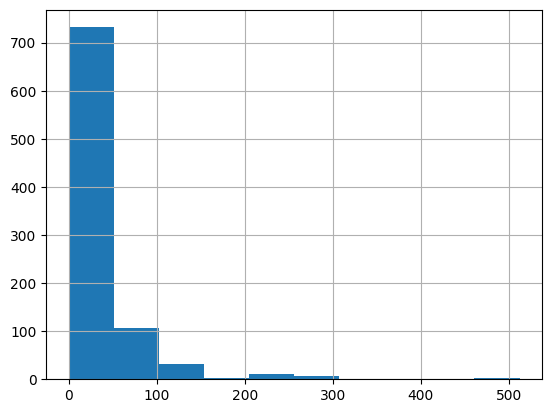

In [11]:
df['Fare'].hist();

In [12]:
df['LogFare'] = np.log(df['Fare']+1)

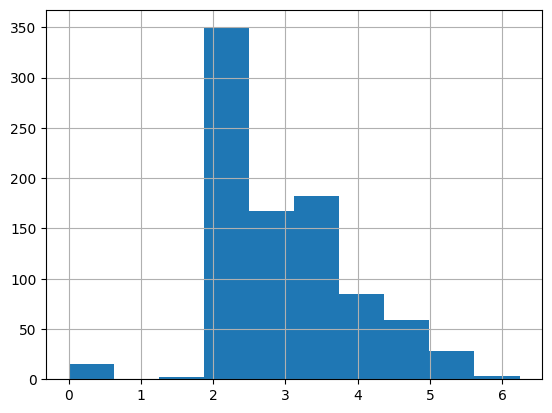

In [13]:
df['LogFare'].hist();

In [14]:
pclasses = sorted(df.Pclass.unique())
pclasses

[np.int64(1), np.int64(2), np.int64(3)]

In [15]:
df.describe(include=[object])

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,891,891
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,1601,B96 B98,S
freq,1,577,7,691,646


In [16]:
df = pd.get_dummies(df, columns=["Sex","Pclass","Embarked"])
df.columns

Index(['PassengerId', 'Survived', 'Name', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'LogFare', 'Sex_female', 'Sex_male',
       'Pclass_1', 'Pclass_2', 'Pclass_3', 'Embarked_C', 'Embarked_Q', 'Embarked_S'],
      dtype='object')

In [17]:
added_cols = ['Sex_male', 'Sex_female', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Embarked_C', 'Embarked_Q', 'Embarked_S']
df[added_cols].head()

,Sex_male,Sex_female,Pclass_1,Pclass_2,Pclass_3,Embarked_C,Embarked_Q,Embarked_S
0,True,False,False,False,True,False,False,True
1,False,True,True,False,False,True,False,False
2,False,True,False,False,True,False,False,True
3,False,True,True,False,False,False,False,True
4,True,False,False,False,True,False,False,True


In [18]:
from torch import tensor

t_dep = tensor(df.Survived)

In [19]:
indep_cols = ['Age', 'SibSp', 'Parch', 'LogFare'] + added_cols

t_indep = tensor(df[indep_cols].to_numpy(dtype=np.float32), dtype=torch.float)
t_indep

tensor([[22.0000,  1.0000,  0.0000,  2.1102,  1.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  1.0000],
        [38.0000,  1.0000,  0.0000,  4.2806,  0.0000,  1.0000,  1.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000],
        [26.0000,  0.0000,  0.0000,  2.1889,  0.0000,  1.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  1.0000],
        [35.0000,  1.0000,  0.0000,  3.9908,  0.0000,  1.0000,  1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  1.0000],
        [35.0000,  0.0000,  0.0000,  2.2028,  1.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  1.0000],
        [24.0000,  0.0000,  0.0000,  2.2469,  1.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000,  1.0000,  0.0000],
        [54.0000,  0.0000,  0.0000,  3.9677,  1.0000,  0.0000,  1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  1.0000],
        ...,
        [25.0000,  0.0000,  0.0000,  2.0857,  1.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  1.0000],
        [39.0000,  0.0000,  5.0000,  3.4054

In [20]:
t_indep.shape

torch.Size([891, 12])

## Setting up a linear model

In [21]:
torch.manual_seed(442)

n_coeff = t_indep.shape[1]
coeffs = torch.rand(n_coeff)-0.5
coeffs

tensor([-0.4629,  0.1386,  0.2409, -0.2262, -0.2632, -0.3147,  0.4876,  0.3136,  0.2799, -0.4392,  0.2103,  0.3625])

In [22]:
t_indep*coeffs

tensor([[-10.1838,   0.1386,   0.0000,  -0.4772,  -0.2632,  -0.0000,   0.0000,   0.0000,   0.2799,  -0.0000,   0.0000,   0.3625],
        [-17.5902,   0.1386,   0.0000,  -0.9681,  -0.0000,  -0.3147,   0.4876,   0.0000,   0.0000,  -0.4392,   0.0000,   0.0000],
        [-12.0354,   0.0000,   0.0000,  -0.4950,  -0.0000,  -0.3147,   0.0000,   0.0000,   0.2799,  -0.0000,   0.0000,   0.3625],
        [-16.2015,   0.1386,   0.0000,  -0.9025,  -0.0000,  -0.3147,   0.4876,   0.0000,   0.0000,  -0.0000,   0.0000,   0.3625],
        [-16.2015,   0.0000,   0.0000,  -0.4982,  -0.2632,  -0.0000,   0.0000,   0.0000,   0.2799,  -0.0000,   0.0000,   0.3625],
        [-11.1096,   0.0000,   0.0000,  -0.5081,  -0.2632,  -0.0000,   0.0000,   0.0000,   0.2799,  -0.0000,   0.2103,   0.0000],
        [-24.9966,   0.0000,   0.0000,  -0.8973,  -0.2632,  -0.0000,   0.4876,   0.0000,   0.0000,  -0.0000,   0.0000,   0.3625],
        ...,
        [-11.5725,   0.0000,   0.0000,  -0.4717,  -0.2632,  -0.0000,   0.0000

In [23]:
vals,indices = t_indep.max(dim=0)
t_indep = t_indep / vals

In [24]:
t_indep*coeffs

tensor([[-0.1273,  0.0173,  0.0000, -0.0765, -0.2632, -0.0000,  0.0000,  0.0000,  0.2799, -0.0000,  0.0000,  0.3625],
        [-0.2199,  0.0173,  0.0000, -0.1551, -0.0000, -0.3147,  0.4876,  0.0000,  0.0000, -0.4392,  0.0000,  0.0000],
        [-0.1504,  0.0000,  0.0000, -0.0793, -0.0000, -0.3147,  0.0000,  0.0000,  0.2799, -0.0000,  0.0000,  0.3625],
        [-0.2025,  0.0173,  0.0000, -0.1446, -0.0000, -0.3147,  0.4876,  0.0000,  0.0000, -0.0000,  0.0000,  0.3625],
        [-0.2025,  0.0000,  0.0000, -0.0798, -0.2632, -0.0000,  0.0000,  0.0000,  0.2799, -0.0000,  0.0000,  0.3625],
        [-0.1389,  0.0000,  0.0000, -0.0814, -0.2632, -0.0000,  0.0000,  0.0000,  0.2799, -0.0000,  0.2103,  0.0000],
        [-0.3125,  0.0000,  0.0000, -0.1438, -0.2632, -0.0000,  0.4876,  0.0000,  0.0000, -0.0000,  0.0000,  0.3625],
        ...,
        [-0.1447,  0.0000,  0.0000, -0.0756, -0.2632, -0.0000,  0.0000,  0.0000,  0.2799, -0.0000,  0.0000,  0.3625],
        [-0.2257,  0.0000,  0.2008, -0.1234

In [25]:
preds = (t_indep*coeffs).sum(axis=1)

In [26]:
preds[:10]

tensor([ 0.1927, -0.6239,  0.0979,  0.2056,  0.0968,  0.0066,  0.1306,  0.3476,  0.1613, -0.6285])

In [27]:
loss = torch.abs(preds-t_dep).mean()
loss

tensor(0.5382)

In [28]:
def calc_preds(coeffs, indeps): return (indeps*coeffs).sum(axis=1)
def calc_loss(coeffs, indeps, deps): return torch.abs(calc_preds(coeffs, indeps)-deps).mean()

## Doing a gradient descent step

In [29]:
coeffs.requires_grad_()

tensor([-0.4629,  0.1386,  0.2409, -0.2262, -0.2632, -0.3147,  0.4876,  0.3136,  0.2799, -0.4392,  0.2103,  0.3625], requires_grad=True)

In [30]:
loss = calc_loss(coeffs, t_indep, t_dep)
loss

tensor(0.5382, grad_fn=<MeanBackward0>)

In [31]:
loss.backward()

In [32]:
coeffs.grad

tensor([-0.0106,  0.0129, -0.0041, -0.0484,  0.2099, -0.2132, -0.1212, -0.0247,  0.1425, -0.1886, -0.0191,  0.2043])

In [33]:
loss = calc_loss(coeffs, t_indep, t_dep)
loss.backward()
coeffs.grad

tensor([-0.0212,  0.0258, -0.0082, -0.0969,  0.4198, -0.4265, -0.2424, -0.0494,  0.2851, -0.3771, -0.0382,  0.4085])

In [34]:
loss = calc_loss(coeffs, t_indep, t_dep)
loss.backward()
with torch.no_grad():
    coeffs.sub_(coeffs.grad * 0.1)
    coeffs.grad.zero_()
    print(calc_loss(coeffs, t_indep, t_dep))

tensor(0.4945)


## Training the linear model

In [35]:
from fastai.data.transforms import RandomSplitter
trn_split,val_split=RandomSplitter(seed=42)(df)

In [36]:
trn_indep,val_indep = t_indep[trn_split],t_indep[val_split]
trn_dep,val_dep = t_dep[trn_split],t_dep[val_split]
len(trn_indep),len(val_indep)

(713, 178)

In [37]:
def update_coeffs(coeffs, lr):
    coeffs.sub_(coeffs.grad * lr)
    coeffs.grad.zero_()

In [38]:
def one_epoch(coeffs, lr):
    loss = calc_loss(coeffs, trn_indep, trn_dep)
    loss.backward()
    with torch.no_grad(): update_coeffs(coeffs, lr)
    print(f"{loss:.3f}", end="; ")
    return float(loss.detach())

In [39]:
def init_coeffs(): return (torch.rand(n_coeff)-0.5).requires_grad_()

In [40]:
_manual_experiment_index = 0
def train_model(epochs=30, lr=0.01):
    # Original schedule and initialization, with extra per-epoch Drive evidence.
    global _manual_experiment_index
    _manual_experiment_index += 1
    torch.manual_seed(442)
    coeffs = init_coeffs()
    history = []
    for i in range(epochs):
        history.append(one_epoch(coeffs, lr=lr))
        state_path = MODELS / f'manual_experiment_{_manual_experiment_index:02d}.pt'
        torch.save({'coeffs': coeffs, 'completed_epochs': i+1, 'requested_epochs': epochs,
                    'lr': lr, 'seed': 442, 'loss': 'mean_absolute_error', 'history': history}, state_path)
        record_stage(f'manual_experiment_{_manual_experiment_index:02d}', completed_epochs=i+1,
                     requested_epochs=epochs, learning_rate=lr, seed=442, loss='mean_absolute_error',
                     loss_history=history, checkpoint=str(state_path))
    with torch.no_grad():
        vp = calc_preds(coeffs, val_indep).reshape(-1)
        truth = val_dep.reshape(-1)
        assert vp.shape == truth.shape
        pd.DataFrame({'validation_position': list(val_split), 'target': truth.numpy(),
                      'prediction': vp.numpy()}).to_csv(RESULTS / f'manual_experiment_{_manual_experiment_index:02d}_validation.csv', index=False)
        record_stage(f'manual_experiment_{_manual_experiment_index:02d}_validation',
                     rows=len(truth), accuracy=float((truth.bool() == (vp > .5)).float().mean()),
                     mean_absolute_error=float((vp-truth).abs().mean()))
    return coeffs

In [41]:
coeffs = train_model(18, lr=0.2)

0.536; 

0.502; 0.477; 0.454; 0.431; 0.409; 0.388; 0.367; 0.349; 

0.336; 0.330; 0.326; 0.329; 0.304; 0.314; 0.296; 

0.300; 0.289; 

In [42]:
def show_coeffs(): return dict(zip(indep_cols, coeffs.requires_grad_(False)))
show_coeffs()

{'Age': tensor(-0.2694),
 'SibSp': tensor(0.0901),
 'Parch': tensor(0.2359),
 'LogFare': tensor(0.0280),
 'Sex_male': tensor(-0.3990),
 'Sex_female': tensor(0.2345),
 'Pclass_1': tensor(0.7232),
 'Pclass_2': tensor(0.4112),
 'Pclass_3': tensor(0.3601),
 'Embarked_C': tensor(0.0955),
 'Embarked_Q': tensor(0.2395),
 'Embarked_S': tensor(0.2122)}

## Measuring accuracy

In [43]:
preds = calc_preds(coeffs, val_indep)

In [44]:
results = val_dep.bool()==(preds>0.5)
results[:16]

tensor([ True,  True,  True,  True,  True,  True,  True,  True,  True,  True, False, False, False,  True,  True, False])

In [45]:
results.float().mean()

tensor(0.7865)

In [46]:
def acc(coeffs): return (val_dep.bool()==(calc_preds(coeffs, val_indep)>0.5)).float().mean()
acc(coeffs)

tensor(0.7865)

## Using sigmoid

In [47]:
preds[:28]

tensor([ 0.8160,  0.1295, -0.0148,  0.1831,  0.1520,  0.1350,  0.7279,  0.7754,  0.3222,  0.6740,  0.0753,  0.0389,  0.2216,  0.7631,
         0.0678,  0.3997,  0.3324,  0.8278,  0.1078,  0.7126,  0.1023,  0.3627,  0.9937,  0.8050,  0.1153,  0.1455,  0.8652,  0.3425])

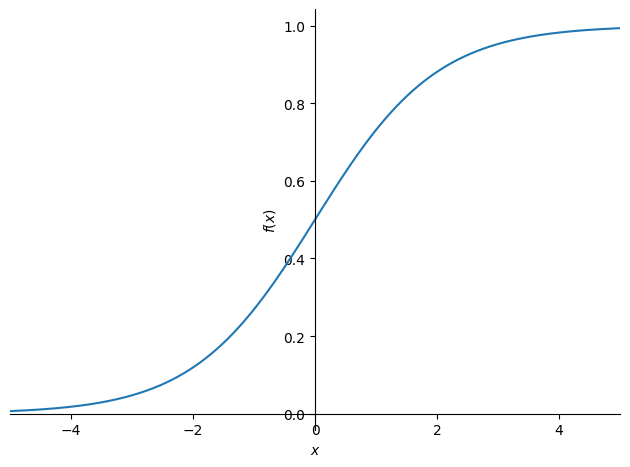

In [48]:
import sympy
_sigmoid_x = sympy.Symbol('x')
sympy.plot(1/(1+sympy.exp(-_sigmoid_x)), (_sigmoid_x, -5, 5), xlim=(-5,5));

In [49]:
def calc_preds(coeffs, indeps): return torch.sigmoid((indeps*coeffs).sum(axis=1))

In [50]:
coeffs = train_model(lr=100)

0.510; 0.327; 0.294; 0.207; 0.201; 0.199; 

0.198; 0.197; 0.196; 0.196; 0.196; 0.195; 0.195; 

0.195; 0.195; 0.195; 0.195; 0.195; 0.194; 0.194; 

0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 

0.194; 0.194; 0.194; 

In [51]:
acc(coeffs)

tensor(0.8258)

In [52]:
show_coeffs()

{'Age': tensor(-1.5061),
 'SibSp': tensor(-1.1575),
 'Parch': tensor(-0.4267),
 'LogFare': tensor(0.2543),
 'Sex_male': tensor(-10.3320),
 'Sex_female': tensor(8.4185),
 'Pclass_1': tensor(3.8389),
 'Pclass_2': tensor(2.1398),
 'Pclass_3': tensor(-6.2331),
 'Embarked_C': tensor(1.4771),
 'Embarked_Q': tensor(2.1168),
 'Embarked_S': tensor(-4.7958)}

## Submitting to Kaggle

In [53]:
tst_df = pd.read_csv(path/'test.csv')

In [54]:
tst_df['Fare'] = tst_df.Fare.fillna(0)

In [55]:
tst_df.fillna(modes, inplace=True)
tst_df['LogFare'] = np.log(tst_df['Fare']+1)
tst_df = pd.get_dummies(tst_df, columns=["Sex","Pclass","Embarked"])

tst_indep = tensor(tst_df[indep_cols].to_numpy(dtype=np.float32), dtype=torch.float)
tst_indep = tst_indep / vals

In [56]:
tst_df['Survived'] = (calc_preds(coeffs, tst_indep)>0.5).int()

In [57]:
sub_df = tst_df[['PassengerId','Survived']]
sub_df.to_csv(RESULTS / 'sub.csv', index=False)
record_stage('sigmoid_test_predictions', rows=len(sub_df), csv=str(RESULTS / 'sub.csv'), test_labels_available=False, submitted=False)

In [58]:
pd.read_csv(RESULTS / 'sub.csv').head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


## Using matrix product

In [59]:
(val_indep*coeffs).sum(axis=1)

tensor([ 12.3288, -14.8119, -15.4540, -13.1513, -13.3512, -13.6469,   3.6248,   5.3429, -22.0878,   3.1233, -21.8742, -15.6421, -21.5504,
          3.9393, -21.9190, -12.0010, -12.3775,   5.3550, -13.5880,  -3.1015, -21.7237, -12.2081,  12.9767,   4.7427, -21.6525, -14.9135,
         -2.7433, -12.3210, -21.5886,   3.9387,   5.3890,  -3.6196, -21.6296, -21.8454,  12.2159,  -3.2275, -12.0289,  13.4560, -21.7230,
         -3.1366, -13.2462, -21.7230, -13.6831,  13.3092, -21.6477,  -3.5868, -21.6854, -21.8316, -14.8158,  -2.9386,  -5.3103, -22.2384,
        -22.1097, -21.7466, -13.3780, -13.4909, -14.8119, -22.0690, -21.6666, -21.7818,  -5.4439, -21.7407, -12.6551, -21.6671,   4.9238,
        -11.5777, -13.3323, -21.9638, -15.3030,   5.0243, -21.7614,   3.1820, -13.4721, -21.7170, -11.6066, -21.5737, -21.7230, -11.9652,
        -13.2382, -13.7599, -13.2170,  13.1347, -21.7049, -21.7268,   4.9207,  -7.3198,  -5.3081,   7.1065,  11.4948, -13.3135, -21.8723,
        -21.7230,  13.3603, -15.56

In [60]:
val_indep@coeffs

tensor([ 12.3288, -14.8119, -15.4540, -13.1513, -13.3511, -13.6468,   3.6248,   5.3429, -22.0878,   3.1233, -21.8742, -15.6421, -21.5504,
          3.9393, -21.9190, -12.0010, -12.3775,   5.3550, -13.5880,  -3.1015, -21.7237, -12.2081,  12.9767,   4.7427, -21.6525, -14.9135,
         -2.7433, -12.3210, -21.5886,   3.9387,   5.3890,  -3.6196, -21.6296, -21.8454,  12.2159,  -3.2275, -12.0289,  13.4560, -21.7230,
         -3.1366, -13.2462, -21.7230, -13.6831,  13.3092, -21.6477,  -3.5868, -21.6854, -21.8316, -14.8158,  -2.9386,  -5.3103, -22.2384,
        -22.1097, -21.7466, -13.3780, -13.4909, -14.8119, -22.0690, -21.6666, -21.7818,  -5.4439, -21.7407, -12.6551, -21.6671,   4.9238,
        -11.5777, -13.3323, -21.9638, -15.3030,   5.0243, -21.7614,   3.1820, -13.4721, -21.7170, -11.6066, -21.5737, -21.7230, -11.9652,
        -13.2382, -13.7599, -13.2170,  13.1347, -21.7049, -21.7268,   4.9207,  -7.3198,  -5.3081,   7.1065,  11.4948, -13.3135, -21.8723,
        -21.7230,  13.3603, -15.56

In [61]:
def calc_preds(coeffs, indeps): return torch.sigmoid(indeps@coeffs)

In [62]:
def init_coeffs(): return (torch.rand(n_coeff, 1)*0.1).requires_grad_()

In [63]:
trn_dep = trn_dep[:,None]
val_dep = val_dep[:,None]

In [64]:
coeffs = train_model(lr=100)

0.512; 0.323; 0.290; 0.205; 0.200; 0.198; 0.197; 0.197; 

0.196; 0.196; 0.196; 0.195; 0.195; 0.195; 0.195; 0.195; 

0.195; 0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 

0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 

In [65]:
acc(coeffs)

tensor(0.8258)

## A neural network

In [66]:
def init_coeffs(n_hidden=20):
    layer1 = (torch.rand(n_coeff, n_hidden)-0.5)/n_hidden
    layer2 = torch.rand(n_hidden, 1)-0.3
    const = torch.rand(1)[0]
    return layer1.requires_grad_(),layer2.requires_grad_(),const.requires_grad_()

In [67]:
import torch.nn.functional as F

def calc_preds(coeffs, indeps):
    l1,l2,const = coeffs
    res = F.relu(indeps@l1)
    res = res@l2 + const
    return torch.sigmoid(res)

In [68]:
def update_coeffs(coeffs, lr):
    for layer in coeffs:
        layer.sub_(layer.grad * lr)
        layer.grad.zero_()

In [69]:
coeffs = train_model(lr=1.4)

0.543; 0.532; 0.520; 0.505; 0.487; 0.466; 0.439; 0.407; 

0.373; 0.343; 0.319; 0.301; 0.286; 0.274; 0.264; 0.256; 

0.250; 0.245; 0.240; 0.237; 0.234; 0.231; 0.229; 0.227; 

0.226; 0.224; 0.223; 0.222; 0.221; 0.220; 

In [70]:
coeffs = train_model(lr=20)

0.543; 0.400; 0.260; 0.390; 0.221; 0.211; 0.197; 0.195; 

0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 

0.193; 0.193; 0.192; 0.192; 0.192; 0.192; 0.192; 0.192; 

0.192; 0.192; 0.192; 0.192; 0.192; 0.192; 0.192; 

In [71]:
acc(coeffs)

tensor(0.8258)

## Deep learning

In [72]:
def init_coeffs():
    hiddens = [10, 10]  # <-- set this to the size of each hidden layer you want
    sizes = [n_coeff] + hiddens + [1]
    n = len(sizes)
    layers = [(torch.rand(sizes[i], sizes[i+1])-0.3)/sizes[i+1]*4 for i in range(n-1)]
    consts = [(torch.rand(1)[0]-0.5)*0.1 for i in range(n-1)]
    for l in layers+consts: l.requires_grad_()
    return layers,consts

In [73]:
import torch.nn.functional as F

def calc_preds(coeffs, indeps):
    layers,consts = coeffs
    n = len(layers)
    res = indeps
    for i,l in enumerate(layers):
        res = res@l + consts[i]
        if i!=n-1: res = F.relu(res)
    return torch.sigmoid(res)

In [74]:
def update_coeffs(coeffs, lr):
    layers,consts = coeffs
    for layer in layers+consts:
        layer.sub_(layer.grad * lr)
        layer.grad.zero_()

In [75]:
coeffs = train_model(lr=4)

0.521; 0.483; 0.427; 0.379; 0.379; 0.379; 0.379; 

0.378; 0.378; 0.378; 0.378; 0.378; 0.378; 0.378; 0.378; 

0.378; 0.377; 0.376; 0.371; 0.333; 0.239; 0.224; 0.208; 

0.204; 0.203; 0.203; 0.207; 0.197; 0.196; 0.195; 

In [76]:
acc(coeffs)

tensor(0.8258)

## Final thoughts

In [77]:
record_stage('reached_final_cell', all_previous_cells_independently_verified=False)
finish_run(COLAB_CONTEXT)

Saved run settings. Save the notebook in Colab to keep its cell outputs.


In [78]:
# Added by the course runner: inspect the executed runtime, not coursework.
import os as _hailong_os, json as _hailong_json, platform as _hailong_platform
_hailong_evidence = {
    'python': _hailong_platform.python_version(),
    'quick_run': bool(globals().get('QUICK_RUN', False)),
    'course_smoke': _hailong_os.environ.get('COURSE_SMOKE', '0'),
    'keras_backend': _hailong_os.environ.get('KERAS_BACKEND'),
    'legacy_keras': _hailong_os.environ.get('TF_USE_LEGACY_KERAS'),
    'base_model_commit': getattr(getattr(globals().get('model'), 'config', None), '_commit_hash', None),
}
_hailong_context = globals().get('COLAB_CONTEXT')
if _hailong_context and _hailong_context['folder'].relative_to(_hailong_context['root']).as_posix().startswith(('03_fastai', '04_fastai_part2')):
    from course_persistence import collect_reuse_evidence as _hailong_collect
    _hailong_evidence['fastai_reuse_evidence'] = _hailong_context['run'].get('reuse_evidence') or _hailong_collect(_hailong_context)
print('__HAILONG_RUNTIME_EVIDENCE__' + _hailong_json.dumps(_hailong_evidence))


__HAILONG_RUNTIME_EVIDENCE__{"python": "3.12.13", "quick_run": false, "course_smoke": "0", "keras_backend": null, "legacy_keras": null, "base_model_commit": null, "fastai_reuse_evidence": {"contract_version": 1, "notebook": "03_fastai/22_original_05_titanic_from_scratch.ipynb", "source_sha256": "4def629b86d6a1cc519fb90268ca2f3774e29cbbb7ef211aa7998bc047cb3074", "helper_sha256": {"03_fastai/convolution_workbook_exercise.py": "ecacb93aef6846c82d6a9eebc4809e1a6766410f04783ac132f247935af3a8fc", "03_fastai/fastai_utils.py": "a03e913e1c07f55aedd56ee6128096f3f952f4f8be22f83c4a22002589c4bd18", "03_fastai/wearable_objective_extension.py": "f9b0a8bf81a5bab8c10aee5e8795e9cef3df58e40925f7705e58301b18b3fbe9", "03_fastai/wearable_utils.py": "6de4ee45118d96e024bd4e0f3fd3552905b38a1ff01c0a5146578bb0d8263db9", "colab_runtime.py": "e11bedb13e1bd71a71c01cc49e558d05c89b057259fe52e64301d0c4d626a140", "course_persistence.py": "f14f7282d4b1e718b01858a61a2dca8b60f5135ba9971fc7923c50bf12cca3d2"}, "persistent_c